# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [ ]:
STUDENT_NAME = 'Ореньчук Юрій'
LIST_NUMBER  = 15

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))


варіант 15, файл lr6_варіант_15.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')


усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [ ]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: потрібно передбачити бінарну мітку «піде / лишиться» за відомими ознаками, це класифікація з учителем (мітка є).

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: відтік становить лише 26 %, тому тривіальна відповідь «ніхто не піде» дає точність 74 %
# при нульовій користі; AUC оцінює саме ранжування клієнтів за ризиком (кого обдзвонювати першим) і не залежить від порога.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: класи незбалансовані, тож стратифікація зберігає частку відтоку в кожній згортці; рядків лише 1200, тому
# 20 навчань (5x4) дають не одне випадкове число, а середнє з розкидом. Один рядок = один клієнт, тож групова схема не потрібна;
# часову схему не беремо, бо мета це оцінити модель на однорідній вибірці (на можливий часовий зсув вказує розділ 6).

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')


рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.262

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [6]:
overview = pd.DataFrame({
    'стовпець':    list(raw.columns),
    'тип':         [str(raw[c].dtype) for c in raw.columns],
    'унікальних':  [raw[c].nunique() for c in raw.columns],
    '% пропусків': [round(raw[c].isna().mean() * 100, 1) for c in raw.columns],
    'приклад':     [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)
display(overview)

# планка для метрики: що дасть модель «ніхто не піде»
print('точність моделі «ніхто не піде»: %.3f' % (1 - raw[TARGET].mean()))


,стовпець,тип,унікальних,% пропусків,приклад
0,сума_повернення_депозиту,float64,313,73.8,416.0
1,дата_розірвання,str,257,73.8,2025-09-27
2,середній_час_відповіді_хв,float64,273,34.6,12.1
3,трафік_ГБ,str,951,5.0,282.8
4,щомісячний_платіж,str,1127,4.0,271.94
5,аварій_на_ділянці_за_квартал,float64,5,3.0,0.0
6,стать,str,6,0.0,жін
7,місто,str,6,0.0,Львів
8,id_клієнта,str,1200,0.0,K150000
9,вік,float64,63,0.0,18.0


точність моделі «ніхто не піде»: 0.738


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# 1) числові колонки, де частина записів — не чисте число
for c in ['щомісячний_платіж', 'трафік_ГБ']:
    s = raw[c].dropna().astype(str)
    bad = s[~s.str.fullmatch(r'-?\d+(\.\d+)?')]
    is_date = bad.str.match(r'^\d{4}-\d{2}-\d{2}')
    print('%-20s нечисловий запис у %2d рядках: з них «дата» %d, «текст з одиницями» %d'
          % (c, len(bad), is_date.sum(), (~is_date).sum()))
    print('   приклади:', bad.head(4).tolist())

# 2) Excel-дата: 1900-01-NN — це число NN, яке Excel «допоміг» перетворити на дату. Це брак, а не дані
print()
print(raw['трафік_ГБ'].astype(str).loc[lambda s: s.str.startswith('1900-')])

# 3) пропуски, що щось означають: порівняємо їх із кількістю звернень у підтримку
print()
print('середній_час_відповіді_хв: пропусків %d (%.1f %%)' % (raw['середній_час_відповіді_хв'].isna().sum(),
      raw['середній_час_відповіді_хв'].isna().mean() * 100))
display(pd.crosstab(raw['середній_час_відповіді_хв'].isna().rename('пропуск'),
                    raw['кількість_звернень_у_підтримку']))


щомісячний_платіж    нечисловий запис у 27 рядках: з них «дата» 0, «текст з одиницями» 27
   приклади: ['373.35 грн', '253.3 грн', '506.57 грн', '355.37 грн']
трафік_ГБ            нечисловий запис у  3 рядках: з них «дата» 3, «текст з одиницями» 0
   приклади: ['1900-01-09 00:00:00', '1900-01-03 00:00:00', '1900-01-16 00:00:00']

372    1900-01-09 00:00:00
870    1900-01-03 00:00:00
995    1900-01-16 00:00:00
Name: трафік_ГБ, dtype: str

середній_час_відповіді_хв: пропусків 415 (34.6 %)


кількість_звернень_у_підтримку,0,1,2,3,4,5,6
пропуск,,,,,,,
False,0,442,239,78,23,1,2
True,415,0,0,0,0,0,0


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця: частина значень — «350.5 грн»
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'            # назва стовпця: у трьох клітинках число перетворилося на дату 1900-01-NN
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = ('пропуск означає, що клієнт жодного разу не звертався у підтримку '
                          '(кількість звернень = 0), тож відповіді просто не було; це не «невідоме значення», '
                          'а «подія не відбулась»')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')


проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [ ]:
DATE_RE = re.compile(r'^\s*\d{4}-\d{2}-\d{2}')
NUM_RE  = re.compile(r'-?\d+(?:[.,]\d+)?')

def to_number(s):
    # Витягує число з колонки, де перемішані числа, текст і дати.
    def one(v):
        if v is None:
            return np.nan
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan
        if isinstance(v, (int, float, np.integer, np.floating)):
            return np.nan if pd.isna(v) else float(v)
        t = str(v).strip()
        if DATE_RE.match(t):
            return np.nan
        m = NUM_RE.search(t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
assert np.isnan(to_number(pd.Series(['1900-01-09 00:00:00']))[0]), 'дата-рядок з CSV теж має стати NaN'
print('to_number працює')


to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

# текст «число + необов'язкова одиниця» (350.5 грн) — на відміну від «Ф-02 Захід» чи «НОМ-027»,
# де число всередині — частина коду, а не величина
NUMLIKE_RE = re.compile(r'^\s*-?\d+(?:[.,]\d+)?\s*[^\W\d_]*\.?\s*$')
EPOCH = pd.Timestamp('2020-01-01')

def build_X(d, drop):
    # Сира таблиця -> матриця ознак. Категорії лишаємо типом category.
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if pd.api.types.is_numeric_dtype(s):                       # числова -> float
            X[c] = s.astype(float); log.append((c, 'число'))
            continue
        nn = s.dropna().astype(str)
        share_date = nn.map(lambda t: bool(DATE_RE.match(t))).mean()
        if share_date > 0.8:                                       # колонка-дата -> порядковий номер дня
            X[c] = (pd.to_datetime(s, errors='coerce') - EPOCH).dt.days.astype(float)
            log.append((c, 'дата -> число (день)'))
            continue
        share_num = nn.map(lambda t: bool(NUMLIKE_RE.match(t)) or bool(DATE_RE.match(t))).mean()
        if share_num > 0.8:                                        # текст із числами -> число
            X[c] = to_number(s); log.append((c, 'число з тексту'))
            continue
        t = s.astype(object).map(lambda v: np.nan if pd.isna(v) else str(v).strip().lower())
        if c == 'стать':                                           # ч/Ч/чол -> «ч», ж/Ж/жін -> «ж»
            t = t.map(lambda v: v if pd.isna(v) else v[0])
        X[c] = t.astype('category'); log.append((c, 'категорія (регістр і пробіли приведено)'))
    return X, pd.DataFrame(log, columns=['стовпець', 'рішення'])


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)


матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення
0,вік,число
1,стать,категорія (регістр і пробіли приведено)
2,місто,категорія (регістр і пробіли приведено)
3,філія,категорія (регістр і пробіли приведено)
4,тариф,категорія (регістр і пробіли приведено)
5,тип_підключення,категорія (регістр і пробіли приведено)
6,спосіб_оплати,категорія (регістр і пробіли приведено)
7,автоплатіж,категорія (регістр і пробіли приведено)
8,кількість_послуг,число
9,місяців_обслуговування,число


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [ ]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),   # +стовпець «було NaN»
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat),
    ], sparse_threshold=0)
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)


# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())


конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.4 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC %.3f ± %.3f — майже ідеальне розділення класів, чого на реальних клієнтських даних '
                  'не буває; спрацювала друга причина (витік), а не якість моделі: серед стовпців є ті, що існують '
                  'лише в клієнтів, які вже пішли'
                  % (auc_naive.mean(), auc_naive.std()))
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)


AUC 1.000 ± 0.000 — майже ідеальне розділення класів, чого на реальних клієнтських даних не буває; спрацювала друга причина (витік), а не якість моделі: серед стовпців є ті, що існують лише в клієнтів, які вже пішли


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    # Для кожного стовпця: наскільки добре його заповненість вгадує клас.
    # Повертає таблицю: ознака, заповнено, частка_відтоку_де_заповнено,
    # частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n1, n0 = int(filled.sum()), int((~filled).sum())
        if n1 >= min_group and n0 >= min_group:          # обидві групи мають бути не мізерними
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a)                         # «заповнено ТІЛЬКИ в тих, хто лишився» теж витік
        else:
            score = np.nan                                # показник недостовірний
        rows.append({'ознака': c, 'заповнено': n1,
                     'частка_відтоку_де_заповнено': y[filled].mean() if n1 else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n0 else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))


,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,дата_розірвання,314,1.000000,0.000000,1.000000
23,сума_повернення_депозиту,314,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,785,0.289172,0.209639,0.546567
12,щомісячний_платіж,1152,0.256076,0.395833,0.513889
16,аварій_на_ділянці_за_квартал,1164,0.260309,0.305556,0.503408
14,трафік_ГБ,1140,0.260526,0.283333,0.502804
0,id_клієнта,1200,0.261667,NaN,NaN
1,вік,1200,0.261667,NaN,NaN
2,стать,1200,0.261667,NaN,NaN
3,місто,1200,0.261667,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',            # проставляється в день розірвання договору; у тих, хто лишився, її немає — це сам результат
    'сума_повернення_депозиту',   # нараховується при закритті договору: депозит повертають лише тим, хто пішов
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)


цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.909 ± 0.020


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# Питання до кожного: ХТО і КОЛИ це заповнює? Підозру викликає поле, яке заповнене в усіх рядках,
# але фіксує дію людини, що вже бачила поведінку клієнта:
print()
display(raw.groupby('кількість_дзвінків_утримання')[TARGET].agg(['mean', 'size']).round(3))


['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']



,mean,size
кількість_дзвінків_утримання,,
0,0.064,824
1,0.675,77
2,0.629,70
3,0.750,68
4,0.690,84
5,0.727,77


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # заповнює відділ утримання, який телефонує тим, хто вже натякнув на розірвання
]
HUMAN_LEAK_WHY = ('поле заповнене в усіх 1200 клієнтів (нуль теж значення), тому «заповненість» не відрізняє класи і '
                  'детектор бачить показник ≈ 0,5; але змістовно це дії людини, яка вже знала про намір клієнта піти: '
                  'у момент звернення дзвінків утримання ще нема (рішення, кому телефонувати, ми ухвалюємо саме зараз)')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))


після вилучення оцінок людини: 21 ознак, AUC 0.830 ± 0.026


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.253,194
Ф-02 Захід,0.277,188
Ф-03 Схід,0.257,191
Ф-04 Південь,0.238,227
Ф-05 Північ,0.245,196
Ф-06 Приміська,0.304,204


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.170,141
2023Q2,0.114,149
2023Q3,0.240,171
2023Q4,0.191,131
2024Q1,0.206,136
2024Q2,0.370,162
2024Q3,0.360,161
2024Q4,0.409,149


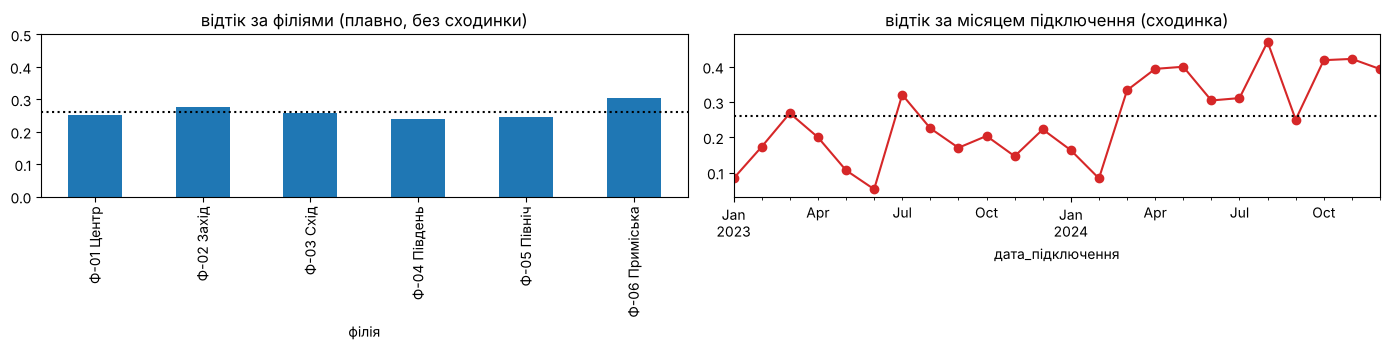

In [19]:
# 1) частка відтоку за філіями
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'})
display(by_branch.round(3))

# 2) частка відтоку за кварталами і місяцями дати підключення
conn = pd.to_datetime(raw['дата_підключення'])
by_quarter = raw.groupby(conn.dt.to_period('Q'))[TARGET].agg(['mean', 'size']).rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'})
display(by_quarter.round(3))

by_month = raw.groupby(conn.dt.to_period('M'))[TARGET].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
by_branch['частка відтоку'].plot.bar(ax=ax[0], color='tab:blue'); ax[0].set_title('відтік за філіями (плавно, без сходинки)')
ax[0].axhline(raw[TARGET].mean(), color='k', ls=':'); ax[0].set_ylim(0, 0.5)
by_month.plot(ax=ax[1], marker='o', color='tab:red'); ax[1].set_title('відтік за місяцем підключення (сходинка)')
ax[1].axhline(raw[TARGET].mean(), color='k', ls=':')
plt.tight_layout(); plt.show()


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- бінарна змінна source: 1 для клієнтів, підключених після дати-зламу -----
# дату зламу шукаємо за даними: перебираємо перші числа місяців і беремо ту межу, де різниця часток відтоку
# найбільша (у стандартних похибках)
dt_conn = pd.to_datetime(raw['дата_підключення'])
cands = []
for t in pd.date_range(dt_conn.min() + pd.DateOffset(months=3), dt_conn.max() - pd.DateOffset(months=3), freq='MS'):
    after = dt_conn >= t
    n1, n0 = int(after.sum()), int((~after).sum())
    if min(n0, n1) < 100:
        continue
    gap = y[after].mean() - y[~after].mean()
    se = np.sqrt(y.mean() * (1 - y.mean()) * (1 / n0 + 1 / n1))
    cands.append((t, gap, gap / se))
BREAK_DATE = max(cands, key=lambda r: abs(r[2]))[0]
source = (dt_conn >= BREAK_DATE).astype(int)
print('дата зламу: %s; до неї відтік %.3f (%d клієнтів), після — %.3f (%d клієнтів)'
      % (BREAK_DATE.date(), y[source == 0].mean(), (source == 0).sum(), y[source == 1].mean(), (source == 1).sum()))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))


дата зламу: 2024-03-01; до неї відтік 0.174 (677 клієнтів), після — 0.375 (523 клієнтів)


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.815
ті самі ознаки передбачають ВІДТІК  : AUC 0.813 ± 0.027


In [21]:
# Додаткова перевірка: чи не передбачається джерело лише тому, що воно пов'язане з відтоком?
# Рахуємо AUC джерела окремо всередині кожного класу (відтік фіксований).
auc_src_within = {}
for k in (0, 1):
    m = (y == k).to_numpy()
    a = cross_val_score(make_pipe(X4[m], logreg()), X4[m], source[m], cv=cv, scoring='roc_auc')
    auc_src_within[k] = a.mean()
    print('AUC джерела серед клієнтів із відтоком=%d: %.3f  (%d клієнтів)' % (k, a.mean(), m.sum()))


AUC джерела серед клієнтів із відтоком=0: 0.814  (886 клієнтів)


AUC джерела серед клієнтів із відтоком=1: 0.803  (314 клієнтів)


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [22]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.909
3. мінус оцінки людини,21,0.830
4. мінус артефакт збору,20,0.813


чесне число: 0.813 ± 0.027


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [23]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = ('після %s частка відтоку стрибком зростає з %.2f до %.2f, а решта ознак передбачає джерело з AUC %.3f '
                '(%.3f і %.3f всередині класів) — класи за часом непорівнянні; дата підключення не є причиною '
                'відтку, а позначає зміну правила обліку, тому модель має працювати за будь-якої дати підключення, '
                'а не вгадувати період; ціна рішення — AUC падає з %.3f до %.3f'
                % (BREAK_DATE.date(), y[source == 0].mean(), y[source == 1].mean(), auc_src.mean(),
                   auc_src_within[0], auc_src_within[1], auc3.mean(), auc4.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)


викинути — після 2024-03-01 частка відтоку стрибком зростає з 0.17 до 0.37, а решта ознак передбачає джерело з AUC 0.815 (0.814 і 0.803 всередині класів) — класи за часом непорівнянні; дата підключення не є причиною відтку, а позначає зміну правила обліку, тому модель має працювати за будь-якої дати підключення, а не вгадувати період; ціна рішення — AUC падає з 0.830 до 0.813


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [24]:
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)


,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.813,0.027,0.4
одне дерево,0.708,0.038,0.4
випадковий ліс,0.812,0.028,5.8
гістограмний бустинг,0.810,0.024,6.2


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [25]:
def paired(a, b):
    # Повертає (середня різниця, півширина 95% інтервалу) для двох масивів AUC на ТИХ САМИХ згортках.
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return d.mean(), half
    # (20 оцінок не зовсім незалежні — навчальні частини перекриваються, — тож інтервал дещо оптимістичний)


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
paired_res = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    paired_res[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))


випадковий ліс         проти логістичної: -0.0010 ± 0.0087   у межах шуму


гістограмний бустинг   проти логістичної: -0.0031 ± 0.0100   у межах шуму


In [26]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
_rf, _hgb = paired_res['випадковий ліс'], paired_res['гістограмний бустинг']
CHOSEN_WHY = ('AUC усіх трьох придатних моделей збігається в межах шуму (логістична %.3f ± %.3f; ліс %+.4f ± %.4f і '
              'бустинг %+.4f ± %.4f до неї — інтервали накривають нуль), тож складніша модель нічого не дає; '
              'логістична найшвидша (%.1f с проти %.1f с у лісу), її коефіцієнти прямо читаються, і вона найпростіша '
              'для супроводу; одне дерево програє явно (%.3f)'
              % (cmp_models.loc['логістична регресія', 'AUC'], cmp_models.loc['логістична регресія', '±'],
                 _rf[0], _rf[1], _hgb[0], _hgb[1],
                 cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                 cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                 cmp_models.loc['одне дерево', 'AUC']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)


обрано: логістична регресія — AUC усіх трьох придатних моделей збігається в межах шуму (логістична 0.813 ± 0.027; ліс -0.0010 ± 0.0087 і бустинг -0.0031 ± 0.0100 до неї — інтервали накривають нуль), тож складніша модель нічого не дає; логістична найшвидша (0.4 с проти 5.8 с у лісу), її коефіцієнти прямо читаються, і вона найпростіша для супроводу; одне дерево програє явно (0.708)


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [27]:
def add_features(X):
    # Додає сконструйовані ознаки. Приймає і повертає матрицю ознак.
    F = X.copy()
    # гіпотеза 1: клієнт, який платить багато за малу швидкість, відчуває «переплату» і частіше йде
    F['переплата_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза 2: важить не кількість звернень, а їхня частота — 3 звернення за пів року і за 5 років різні речі
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # гіпотеза 3: пакет із кількох послуг дає клієнту «ціну за послугу» нижчу, ніж окремі — він дорожить пакетом
    F['платіж_на_послугу'] = F['щомісячний_платіж'] / F['кількість_послуг']
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))


було 20 ознак, стало 23


In [28]:
t0 = time.time()
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
time_feat = time.time() - t0
m, h = paired(base, auc5)
m_feat, h_feat = m, h
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))


з новими ознаками: AUC 0.814 ± 0.027
приріст проти базового набору: +0.0009 ± 0.0017   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [29]:
_m_rf, _h_rf = paired_res['випадковий ліс']
FEATURES_VS_MODEL = ('жоден шлях не дав значущого приросту: нові ознаки %+.4f ± %.4f (логістична, %.1f с на 20 навчань), '
                     'складніша модель (ліс) %+.4f ± %.4f за %.1f с — обидва інтервали накривають нуль; ліс дорожчий '
                     'у ~%.0f разів, а виграшу немає, бо сигнал уже лежить у вихідних ознаках, і лінійна модель його '
                     'вичерпала'
                     % (m_feat, h_feat, time_feat, _m_rf, _h_rf, cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                        cmp_models.loc['випадковий ліс', 'с на 100 навчань'] /
                        max(cmp_models.loc['логістична регресія', 'с на 100 навчань'], 0.1)))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)


жоден шлях не дав значущого приросту: нові ознаки +0.0009 ± 0.0017 (логістична, 0.6 с на 20 навчань), складніша модель (ліс) -0.0010 ± 0.0087 за 5.8 с — обидва інтервали накривають нуль; ліс дорожчий у ~14 разів, а виграшу немає, бо сигнал уже лежить у вихідних ознаках, і лінійна модель його вичерпала


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [30]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.843
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

стовпців після кодування: 102 -> вихідних ознак: 23


,вбудована важливість
номер_договору_серія,0.1084
щомісячний_платіж,0.0892
переплата_за_Мбіт,0.0679
трафік_МБ,0.0658
швидкість_тарифу_Мбіт,0.0632
трафік_ГБ,0.0622
вік,0.0618
місяців_обслуговування,0.0542
платіж_на_послугу,0.0504
звернень_на_місяць,0.0486


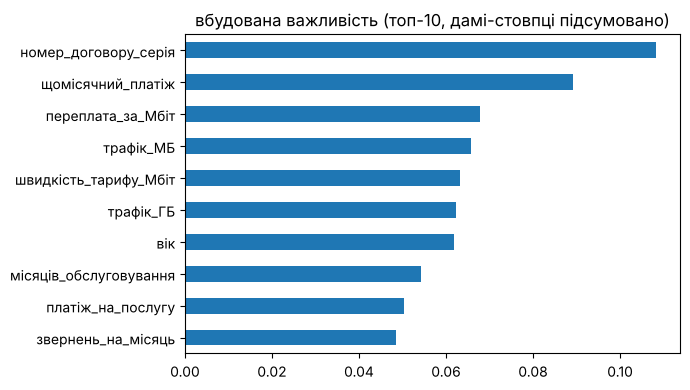

In [31]:
prep = model.named_steps['prep']
rf_clf = model.named_steps['clf']
feat_names = prep.get_feature_names_out()
cat_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']

def source_feature(n):
    # ім'я після перетворення -> вихідна ознака (дамі-стовпці категорії та індикатор пропуску повертаються до неї)
    kind, rest = n.split('__', 1)
    if rest.startswith('missingindicator_'):
        return rest[len('missingindicator_'):]
    if kind == 'cat':
        for c in sorted(cat_cols, key=len, reverse=True):
            if rest.startswith(c + '_'):
                return c
    return rest

gini_raw = pd.Series(rf_clf.feature_importances_, index=feat_names)
gini_imp = gini_raw.groupby([source_feature(n) for n in feat_names]).sum().sort_values(ascending=False)
print('стовпців після кодування: %d -> вихідних ознак: %d' % (len(feat_names), len(gini_imp)))
display(gini_imp.head(10).to_frame('вбудована важливість').round(4))

gini_imp.head(10).iloc[::-1].plot.barh(figsize=(7, 4), color='tab:blue')
plt.title('вбудована важливість (топ-10, дамі-стовпці підсумовано)'); plt.tight_layout(); plt.show()


### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [32]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
місяців_обслуговування,0.029189
звернень_на_місяць,0.025914
вік,0.025468
трафік_МБ,0.025436
швидкість_тарифу_Мбіт,0.021679
щомісячний_платіж,0.017581
переплата_за_Мбіт,0.006863
кількість_послуг,0.006627
трафік_ГБ,0.005347
середній_час_відповіді_хв,0.004977


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [33]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp,
                        '± перестановочної': pd.Series(perm.importances_std, index=FINAL_X.columns)})
cmp_imp = cmp_imp.sort_values('вбудована', ascending=False)
display(cmp_imp.round(4))

# кандидати: топ-5 за вбудованою
print('топ-5 за вбудованою — і що вони мають за перестановочною:')
display(cmp_imp.head(5).round(4))


,вбудована,перестановочна,± перестановочної
номер_договору_серія,0.1084,0.0031,0.0043
щомісячний_платіж,0.0892,0.0176,0.0067
переплата_за_Мбіт,0.0679,0.0069,0.0041
трафік_МБ,0.0658,0.0254,0.0058
швидкість_тарифу_Мбіт,0.0632,0.0217,0.0043
трафік_ГБ,0.0622,0.0053,0.0043
вік,0.0618,0.0255,0.0070
місяців_обслуговування,0.0542,0.0292,0.0053
платіж_на_послугу,0.0504,0.0023,0.0020
звернень_на_місяць,0.0486,0.0259,0.0057


топ-5 за вбудованою — і що вони мають за перестановочною:


,вбудована,перестановочна,± перестановочної
номер_договору_серія,0.1084,0.0031,0.0043
щомісячний_платіж,0.0892,0.0176,0.0067
переплата_за_Мбіт,0.0679,0.0069,0.0041
трафік_МБ,0.0658,0.0254,0.0058
швидкість_тарифу_Мбіт,0.0632,0.0217,0.0043


In [34]:
FAKE_IMPORTANT = 'номер_договору_серія'        # назва ознаки
_g, _p, _s = (cmp_imp.loc[FAKE_IMPORTANT, 'вбудована'], cmp_imp.loc[FAKE_IMPORTANT, 'перестановочна'],
              cmp_imp.loc[FAKE_IMPORTANT, '± перестановочної'])
_g_rank = list(cmp_imp.index).index(FAKE_IMPORTANT) + 1
_p_best = cmp_imp['перестановочна'].max()
FAKE_IMPORTANT_WHY = ('за вбудованою це %d-та ознака (%.3f — найбільша серед усіх), а перестановочна лише %.4f ± %.4f проти %.4f '
                      'у найкращої; це службовий код без змістового зв\'язку з відтоком (χ²-тест p = %.2f), 55 його значень '
                      'дають дереву безліч можливих порогів-розбиттів, і дерево завжди знаходить такі, що на навчальних даних '
                      'трохи зменшують неоднорідність — це «запам\'ятовування», а не закономірність; на нових клієнтах ефекту нема. '
                      'Те саме, але слабше, з «скоринг_партнера» (1200 унікальних значень, перестановочна %.4f)'
                      % (_g_rank, _g, _p, _s, _p_best,
                         stats.chi2_contingency(pd.crosstab(raw['номер_договору_серія'], y))[1],
                         cmp_imp.loc['скоринг_партнера', 'перестановочна']))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)
print(FAKE_IMPORTANT_WHY)


хибно важлива ознака: номер_договору_серія
за вбудованою це 1-та ознака (0.108 — найбільша серед усіх), а перестановочна лише 0.0031 ± 0.0043 проти 0.0292 у найкращої; це службовий код без змістового зв'язку з відтоком (χ²-тест p = 0.13), 55 його значень дають дереву безліч можливих порогів-розбиттів, і дерево завжди знаходить такі, що на навчальних даних трохи зменшують неоднорідність — це «запам'ятовування», а не закономірність; на нових клієнтах ефекту нема. Те саме, але слабше, з «скоринг_партнера» (1200 унікальних значень, перестановочна 0.0022)


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [35]:
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr().abs()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(num_cols) for b in num_cols[i + 1:] if corr.loc[a, b] > 0.97]
display(pd.DataFrame(pairs, columns=['ознака A', 'ознака B', '|r|']).round(4))


,ознака A,ознака B,|r|
0,трафік_ГБ,трафік_МБ,0.9997


In [36]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']        # дві ознаки, що вимірюють те саме (МБ ≈ 1024 × ГБ)
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# приберіть DUP_PAIR[1], навчіть заново на тому самому поділі, порахуйте перестановочну
X_nodup = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(X_nodup, y, test_size=0.3, stratify=y, random_state=SEED)
model_d = make_pipe(X_nodup, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_d, ytr_d)
perm_d = permutation_importance(model_d, Xte_d, yte_d, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_d_imp = pd.Series(perm_d.importances_mean, index=X_nodup.columns)
print('\nбез %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_d_imp[DUP_PAIR[0]]))
auc_nodup = roc_auc_score(yte_d, model_d.predict_proba(Xte_d)[:, 1])
print('   AUC моделі: %.4f (з обома %.4f) — майже не змінилась, бо інформація про трафік лишилась в одній з колонок'
      % (auc_nodup, auc_hold))


у повній моделі:
   трафік_ГБ                    +0.0053
   трафік_МБ                    +0.0254



без трафік_МБ:
   трафік_ГБ                    +0.0356
   AUC моделі: 0.8364 (з обома 0.8426) — майже не змінилась, бо інформація про трафік лишилась в одній з колонок


In [37]:
_r = FINAL_X[DUP_PAIR].corr().iloc[0, 1]
DUP_EXPLANATION = ('%s і %s — той самий трафік у ГБ і в МБ (|r| = %.4f). У повній моделі перестановочна важливість обох мала '
                   '(%.4f і %.4f): коли перемішується одна, модель бере ту саму інформацію з другої. Після вилучення %s '
                   'важливість %s зросла з %.4f до %.4f (у %.1f раза), а AUC моделі майже не змінилась (%.4f проти %.4f) — отже разом вони важливі, '
                   'а поодинці здаються непотрібними. Метод не бреше: він точно відповідає на питання «наскільки гірше '
                   'без цієї ознаки», а хибний лише висновок «важливість мала — ознаку можна викинути».'
                   % (DUP_PAIR[0], DUP_PAIR[1], _r, perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], DUP_PAIR[1], DUP_PAIR[0],
                      perm_imp[DUP_PAIR[0]], perm_d_imp[DUP_PAIR[0]], perm_d_imp[DUP_PAIR[0]] / perm_imp[DUP_PAIR[0]],
                      auc_nodup, auc_hold))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)


трафік_ГБ і трафік_МБ — той самий трафік у ГБ і в МБ (|r| = 0.9997). У повній моделі перестановочна важливість обох мала (0.0053 і 0.0254): коли перемішується одна, модель бере ту саму інформацію з другої. Після вилучення трафік_МБ важливість трафік_ГБ зросла з 0.0053 до 0.0356 (у 6.7 раза), а AUC моделі майже не змінилась (0.8364 проти 0.8426) — отже разом вони важливі, а поодинці здаються непотрібними. Метод не бреше: він точно відповідає на питання «наскільки гірше без цієї ознаки», а хибний лише висновок «важливість мала — ознаку можна викинути».


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

топ-3 числові: ['місяців_обслуговування', 'звернень_на_місяць', 'вік']


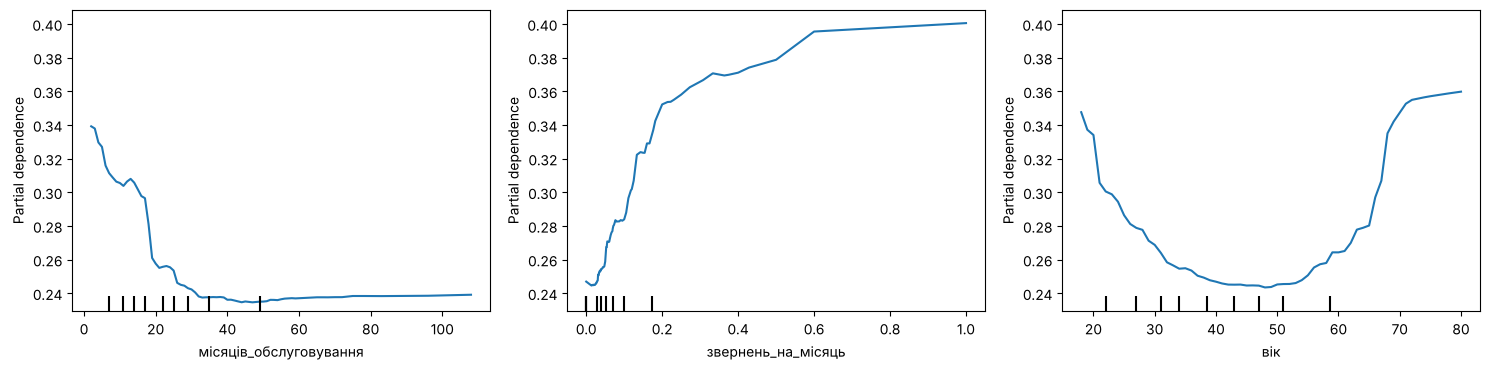

місяців_обслуговування     від 0.327 (при 5) до 0.236 (при 55); мінімум 0.235 при 48.1


звернень_на_місяць         від 0.247 (при 0) до 0.362 (при 0.273); мінімум 0.245 при 0.0188


вік                        від 0.348 (при 18) до 0.279 (при 63.6); мінімум 0.244 при 49.4


In [38]:
from sklearn.inspection import PartialDependenceDisplay

# три найважливіші ЧИСЛОВІ ознаки за перестановочною; беремо лише ті, де нема пропусків (інакше сітка порожня)
num_ranked = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category']
top3_num = [c for c in num_ranked if FINAL_X[c].notna().all()][:3]
print('топ-3 числові:', top3_num)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
PartialDependenceDisplay.from_estimator(model, Xte, features=top3_num, kind='average', ax=ax)
plt.tight_layout(); plt.show()

# те саме числами: значення середнього прогнозу на краях і мінімум
for c in top3_num:
    r = partial_dependence(model, Xte, [c], kind='average', grid_resolution=30)
    g = r.get('grid_values', r.get('values'))[0]; v = r['average'][0]
    print('%-26s від %.3f (при %.3g) до %.3f (при %.3g); мінімум %.3f при %.3g'
          % (c, v[0], g[0], v[-1], g[-1], v.min(), g[np.argmin(v)]))


In [39]:
# Що означає форма кривих (читаємо з графіка і чисел вище):
PDP_READING = {
    'місяців_обслуговування': 'монотонно спадає: чим давніший клієнт, тим нижчий ризик; найвищий — у перші місяці обслуговування',
    'звернень_на_місяць': 'зростає: чим частіше клієнт звертається в підтримку (на місяць стажу), тим вищий ризик відтоку',
    'вік': 'U-подібна: ризик найвищий у наймолодших, мінімальний у віці близько 45–50 років і знову зростає після 55–60 років',
}
for k, v in PDP_READING.items():
    print('%-26s %s' % (k, v))


місяців_обслуговування     монотонно спадає: чим давніший клієнт, тим нижчий ризик; найвищий — у перші місяці обслуговування
звернень_на_місяць         зростає: чим частіше клієнт звертається в підтримку (на місяць стажу), тим вищий ризик відтоку
вік                        U-подібна: ризик найвищий у наймолодших, мінімальний у віці близько 45–50 років і знову зростає після 55–60 років


### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

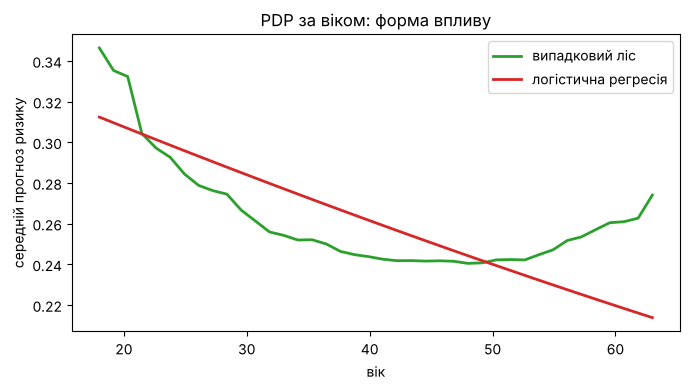

ліс: ризик 0.346 у 18 років -> мінімум 0.240 у 48 років -> 0.274 у 63 років
логістична: монотонна? спадає на всьому діапазоні — True


In [40]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ліс і логістична регресія на одному рисунку (PDP на повній матриці)
lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(7, 4))
curves = {}
for name, mdl, col in [('випадковий ліс', model, 'tab:green'), ('логістична регресія', lr_model, 'tab:red')]:
    r = partial_dependence(mdl, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
    g = r.get('grid_values', r.get('values'))[0]; v = r['average'][0]
    curves[name] = (g, v)
    ax.plot(g, v, label=name, color=col, lw=2)
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній прогноз ризику'); ax.legend(); ax.set_title('PDP за віком: форма впливу')
plt.tight_layout(); plt.show()

g_rf, v_rf = curves['випадковий ліс']; g_lr, v_lr = curves['логістична регресія']
print('ліс: ризик %.3f у %.0f років -> мінімум %.3f у %.0f років -> %.3f у %.0f років'
      % (v_rf[0], g_rf[0], v_rf.min(), g_rf[np.argmin(v_rf)], v_rf[-1], g_rf[-1]))
print('логістична: монотонна? спадає на всьому діапазоні — %s' % bool(np.all(np.diff(v_lr) < 0)))


In [41]:
AGE_MIN_RF = float(g_rf[np.argmin(v_rf)])
NONLINEAR_MEANING = ('ризик відтоку за віком U-подібний: найвищий у наймолодших (%.2f у %.0f років), мінімальний у віці близько '
                     '%.0f років (%.2f), а після 55–60 років знову зростає (%.2f у %.0f); логістична регресія показує лише '
                     'пряму лінію вниз (від %.2f до %.2f) і зростання в літньому віці не бачить. Гіпотеза змісту: молодь '
                     'легко змінює провайдера, а літнім клієнтам складніше з налаштуванням і підтримкою'
                     % (v_rf[0], g_rf[0], AGE_MIN_RF, v_rf.min(), v_rf[-1], g_rf[-1], v_lr[0], v_lr[-1]))
NONLINEAR_FIX = ('додати ознаку «квадрат відхилення від найкращого віку» (вік − %.0f)², яка зростає в обидва боки від '
                 'мінімуму; лінійна модель отримає цю параболу як один зі своїх доданків' % AGE_MIN_RF)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)


ризик відтоку за віком U-подібний: найвищий у наймолодших (0.35 у 18 років), мінімальний у віці близько 48 років (0.24), а після 55–60 років знову зростає (0.27 у 63); логістична регресія показує лише пряму лінію вниз (від 0.31 до 0.21) і зростання в літньому віці не бачить. Гіпотеза змісту: молодь легко змінює провайдера, а літнім клієнтам складніше з налаштуванням і підтримкою
додати ознаку «квадрат відхилення від найкращого віку» (вік − 48)², яка зростає в обидва боки від мінімуму; лінійна модель отримає цю параболу як один зі своїх доданків


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [42]:
# 1) значення, при якому ризик мінімальний — з PDP лісу
AGE_MIN = round(AGE_MIN_RF)
# 2) ознака «квадрат відхилення від цього значення»
Xq = FINAL_X.copy()
Xq['вік_відхилення_кв'] = (Xq['вік'] - AGE_MIN) ** 2
# 3) парне порівняння ЛОГІСТИЧНОЇ регресії з нею і без неї (однакові згортки cv)
lr_without = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
lr_with    = cross_val_score(make_pipe(Xq, logreg()), Xq, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(lr_without, lr_with)
print('мінімум ризику за PDP: %d років' % AGE_MIN)
print('логістична без ознаки: AUC %.3f ± %.3f' % (lr_without.mean(), lr_without.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (lr_with.mean(), lr_with.std()))
print('приріст: %+.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

# для порівняння: ліс цю форму бачив і сам
rf_without = cross_val_score(make_pipe(FINAL_X, RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
                             FINAL_X, y, cv=cv, scoring='roc_auc')
rf_with = cross_val_score(make_pipe(Xq, RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
                          Xq, y, cv=cv, scoring='roc_auc')
m_qrf, h_qrf = paired(rf_without, rf_with)
print('ліс, той самий дослід: %+.4f ± %.4f  %s (приріст у %.1f раза менший, ніж у логістичної: ліс частково бачив цю форму сам)'
      % (m_qrf, h_qrf, 'значуще' if abs(m_qrf) > h_qrf else 'у межах шуму', m_q / max(m_qrf, 1e-9)))


мінімум ризику за PDP: 48 років
логістична без ознаки: AUC 0.814 ± 0.027
логістична з ознакою : AUC 0.840 ± 0.025
приріст: +0.0260 ± 0.0060   значуще


ліс, той самий дослід: +0.0102 ± 0.0063  значуще (приріст у 2.6 раза менший, ніж у логістичної: ліс частково бачив цю форму сам)


In [43]:
QUAD_GAIN = float(m_q)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)


приріст від сконструйованої ознаки: +0.0260


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

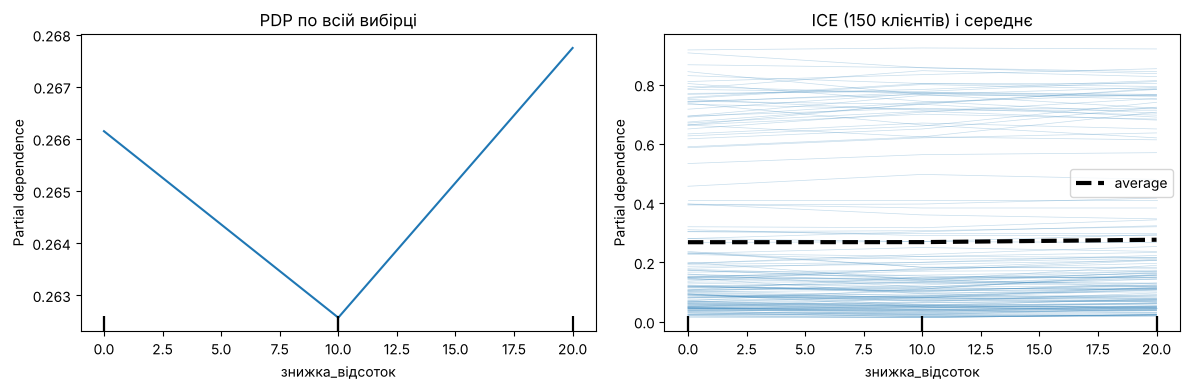

PDP по всій вибірці: від 0.266 (знижка 0) до 0.268 (знижка 20): різниця лише +0.002


In [44]:
# 1) звичайний PDP і 2) ICE для знижка_відсоток — на ПОВНІЙ матриці
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
ax[0].set_title('PDP по всій вибірці')
PartialDependenceDisplay.from_estimator(model, FINAL_X.sample(150, random_state=SEED), ['знижка_відсоток'],
                                        kind='both', ax=ax[1], ice_lines_kw={'alpha': 0.25, 'color': 'tab:blue'},
                                        pd_line_kw={'color': 'k', 'lw': 3})
ax[1].set_title('ICE (150 клієнтів) і середнє')
plt.tight_layout(); plt.show()

r = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
pdp_all = r['average'][0]
print('PDP по всій вибірці: від %.3f (знижка 0) до %.3f (знижка 20): різниця лише %+.3f' % (pdp_all[0], pdp_all[-1], pdp_all[-1] - pdp_all[0]))


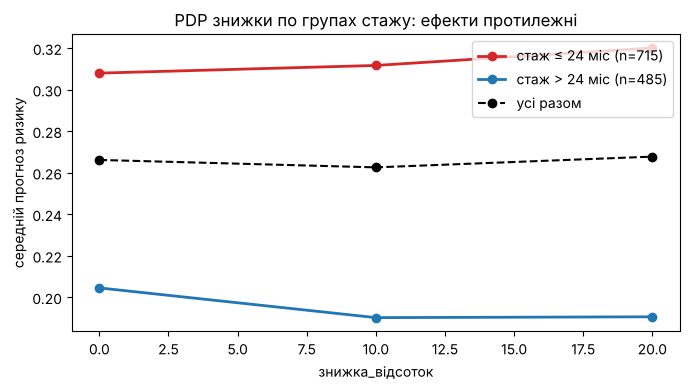

стаж ≤ 24 міс  від 0.308 (знижка 0) до 0.320 (знижка 20)
стаж > 24 міс  від 0.205 (знижка 0) до 0.191 (знижка 20)


In [45]:
# 3) PDP окремо для стажу ≤ 24 і > 24 місяців
mask_new = FINAL_X['місяців_обслуговування'] <= 24
fig, ax = plt.subplots(figsize=(7, 4))
pdp_groups = {}
for label, mask, col in [('стаж ≤ 24 міс', mask_new, 'tab:red'), ('стаж > 24 міс', ~mask_new, 'tab:blue')]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    g = r.get('grid_values', r.get('values'))[0]; v = r['average'][0]
    pdp_groups[label] = v
    ax.plot(g, v, marker='o', label='%s (n=%d)' % (label, mask.sum()), color=col, lw=2)
ax.plot(g, pdp_all, marker='o', color='k', ls='--', label='усі разом')
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середній прогноз ризику'); ax.legend()
ax.set_title('PDP знижки по групах стажу: ефекти протилежні')
plt.tight_layout(); plt.show()
for k, v in pdp_groups.items():
    print('%-14s від %.3f (знижка 0) до %.3f (знижка 20)' % (k, v[0], v[-1]))


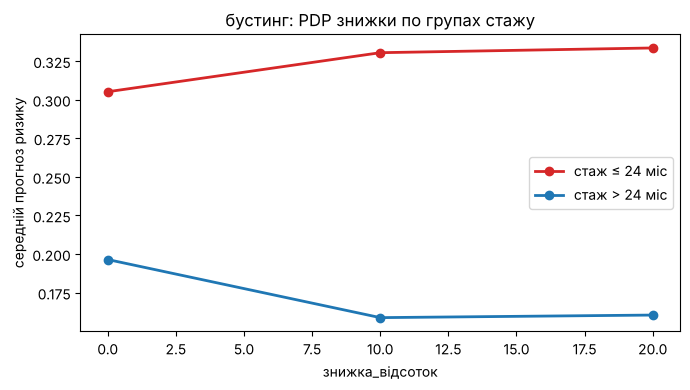

стаж ≤ 24 міс  від 0.305 (знижка 0) до 0.334 (знижка 20): +0.028
стаж > 24 міс  від 0.196 (знижка 0) до 0.160 (знижка 20): -0.036
ICE лісу майже пласкі: ліс використовує знижку слабо (перестановочна 0.0039)


In [46]:
# Ліс слабо вивчив цю взаємодію (знижка в нього маловажлива, ICE майже пласкі), хоча в сирих даних вона сильна.
# Перевіряємо дрібнішим бустингом: чи бачить він протилежні напрямки в двох групах стажу?
hgb_m = make_pipe(FINAL_X, HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                           random_state=SEED)).fit(Xtr, ytr)
hgb_groups = {}
fig, ax = plt.subplots(figsize=(7, 4))
for label, mask, col in [('стаж ≤ 24 міс', mask_new, 'tab:red'), ('стаж > 24 міс', ~mask_new, 'tab:blue')]:
    r = partial_dependence(hgb_m, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    g = r.get('grid_values', r.get('values'))[0]; v = r['average'][0]
    hgb_groups[label] = v
    ax.plot(g, v, marker='o', color=col, lw=2, label=label)
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середній прогноз ризику'); ax.legend()
ax.set_title('бустинг: PDP знижки по групах стажу')
plt.tight_layout(); plt.show()
for k, v in hgb_groups.items():
    print('%-14s від %.3f (знижка 0) до %.3f (знижка 20): %+.3f' % (k, v[0], v[-1], v[-1] - v[0]))
print('ICE лісу майже пласкі: ліс використовує знижку слабо (перестановочна %.4f)' % perm_imp['знижка_відсоток'])


### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [47]:
raw_t = raw.assign(група_стажу=np.where(raw['місяців_обслуговування'] <= 24, 'стаж ≤ 24', 'стаж > 24'))
emp_rate = raw_t.pivot_table(index='знижка_відсоток', columns='група_стажу', values=TARGET, aggfunc='mean')
emp_n = raw_t.pivot_table(index='знижка_відсоток', columns='група_стажу', values=TARGET, aggfunc='size')
print('емпірична частка відтоку (сирі дані):'); display(emp_rate.round(3))
print('розмір груп:'); display(emp_n)


емпірична частка відтоку (сирі дані):


група_стажу,стаж > 24,стаж ≤ 24
знижка_відсоток,,
0,0.234,0.294
10,0.119,0.341
20,0.072,0.395


розмір груп:


група_стажу,стаж > 24,стаж ≤ 24
знижка_відсоток,,
0,188,279
10,159,246
20,138,190


In [48]:
INTERACTION_FOUND = ('знижка діє в протилежні боки залежно від стажу: у клієнтів зі стажем до 24 міс відтік РОСТЕ зі знижкою '
                     '(%.2f -> %.2f -> %.2f при 0 / 10 / 20 %%), а в клієнтів зі стажем понад 24 міс ПАДАЄ (%.2f -> %.2f -> %.2f); '
                     'тому загальний PDP лісу майже плаский (%.3f -> %.3f): протилежні ефекти гасять один одного. Ліс відтворює це слабко '
                     '(ICE майже пласкі, бо знижка в нього маловажлива), зате бустинг у групах дає протилежні зміни (%+.3f у стажу ≤ 24 і '
                     '%+.3f у стажу > 24), а сирі дані — найсильніші, бо не враховують інші ознаки'
                     % (emp_rate.loc[0, 'стаж ≤ 24'], emp_rate.loc[10, 'стаж ≤ 24'], emp_rate.loc[20, 'стаж ≤ 24'],
                        emp_rate.loc[0, 'стаж > 24'], emp_rate.loc[10, 'стаж > 24'], emp_rate.loc[20, 'стаж > 24'],
                        pdp_all[0], pdp_all[-1],
                        hgb_groups['стаж ≤ 24 міс'][-1] - hgb_groups['стаж ≤ 24 міс'][0],
                        hgb_groups['стаж > 24 міс'][-1] - hgb_groups['стаж > 24 міс'][0]))
BUSINESS_ACTION = ('пропонувати знижку у ролі «утримати» лише давнім клієнтам (понад 24 міс), де вона знижує відтік; новим '
                   'клієнтам знижку не пропонувати без перевірки. Застереження: це спостережні дані — знижки видавали не '
                   'навмання (можливо, вже незадоволеним новим клієнтам), тому причинність треба перевірити невеликим '
                   'A/B-тестом')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)


знижка діє в протилежні боки залежно від стажу: у клієнтів зі стажем до 24 міс відтік РОСТЕ зі знижкою (0.29 -> 0.34 -> 0.39 при 0 / 10 / 20 %), а в клієнтів зі стажем понад 24 міс ПАДАЄ (0.23 -> 0.12 -> 0.07); тому загальний PDP лісу майже плаский (0.266 -> 0.268): протилежні ефекти гасять один одного. Ліс відтворює це слабко (ICE майже пласкі, бо знижка в нього маловажлива), зате бустинг у групах дає протилежні зміни (+0.028 у стажу ≤ 24 і -0.036 у стажу > 24), а сирі дані — найсильніші, бо не враховують інші ознаки
пропонувати знижку у ролі «утримати» лише давнім клієнтам (понад 24 міс), де вона знижує відтік; новим клієнтам знижку не пропонувати без перевірки. Застереження: це спостережні дані — знижки видавали не навмання (можливо, вже незадоволеним новим клієнтам), тому причинність треба перевірити невеликим A/B-тестом


In [49]:
# Замикаємо цикл: взаємодію можна «підказати» лінійній моделі окремою ознакою і виміряти приріст (парно)
Xi = FINAL_X.copy()
Xi['знижка_x_новий'] = Xi['знижка_відсоток'] * (Xi['місяців_обслуговування'] <= 24).astype(float)
lr_inter = cross_val_score(make_pipe(Xi, logreg()), Xi, y, cv=cv, scoring='roc_auc')
m_i, h_i = paired(lr_without, lr_inter)
print('логістична з ознакою «знижка × новий клієнт»: AUC %.3f ± %.3f; приріст %+.4f ± %.4f  %s'
      % (lr_inter.mean(), lr_inter.std(), m_i, h_i, 'значуще' if abs(m_i) > h_i else 'у межах шуму'))


логістична з ознакою «знижка × новий клієнт»: AUC 0.830 ± 0.025; приріст +0.0168 ± 0.0044  значуще


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [50]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 102)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

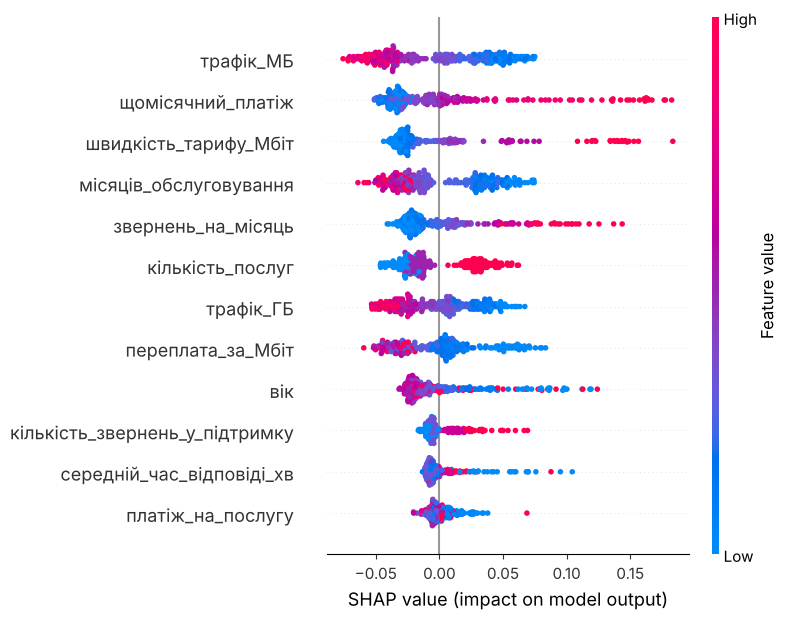

In [51]:
clean_names = [n.split('__', 1)[1] for n in feat_names]
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=clean_names, max_display=12)


In [52]:
# середня абсолютна величина внеску по вихідних ознаках (дамі-стовпці підсумовано)
mean_abs = (pd.Series(np.abs(sv1).mean(axis=0), index=feat_names)
            .groupby([source_feature(n) for n in feat_names]).sum().sort_values(ascending=False))
display(mean_abs.head(8).to_frame('середній |внесок Шеплі|').round(4))


,середній |внесок Шеплі|
трафік_МБ,0.0382
щомісячний_платіж,0.0375
номер_договору_серія,0.0359
швидкість_тарифу_Мбіт,0.0344
місяців_обслуговування,0.0317
трафік_ГБ,0.0268
звернень_на_місяць,0.0266
переплата_за_Мбіт,0.0265


### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [53]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# три найбільші за модулем внески (по вихідних ознаках) для цього клієнта
row = pd.Series(sv1[idx], index=feat_names).groupby([source_feature(n) for n in feat_names]).sum()
top3_contrib = row.reindex(row.abs().sort_values(ascending=False).index).head(3)
base_val = np.ravel(expl.expected_value)[-1]
print('базовий рівень (середній прогноз): %.3f; сума всіх внесків: %+.3f' % (base_val, row.sum()))
vals = Xte.iloc[idx]
for f, v in top3_contrib.items():
    print('  %-26s внесок %+.3f   значення ознаки у клієнта: %s' % (f, v, vals[f]))


ризик клієнта: 0.843
базовий рівень (середній прогноз): 0.262; сума всіх внесків: +0.581
  щомісячний_платіж          внесок +0.147   значення ознаки у клієнта: 647.22
  швидкість_тарифу_Мбіт      внесок +0.134   значення ознаки у клієнта: 1000.0
  переплата_за_Мбіт          внесок +0.070   значення ознаки у клієнта: 0.64722


In [54]:
p_client = model.predict_proba(Xte)[:SAMPLE, 1][idx]
EXPLANATION_FOR_MANAGER = (
    'Шанс, що цей клієнт піде, ми оцінюємо у %.0f %% — проти %.0f %% у середньому по базі. Найбільше цей ризик піднімають '
    'три обставини, і всі вони про тариф: клієнт платить дуже багато (%.0f грн на місяць) — це додає близько %.0f процентних '
    'пунктів ризику; він користується найшвидшим тарифом (%.0f Мбіт/с) — ще близько %.0f пунктів; і платить відносно '
    'багато за кожен мегабіт швидкості — ще близько %.0f пунктів. Інакше кажучи, це клієнт із дорогим швидкісним тарифом, '
    'а такі клієнти раніше частіше розривали договір. Це лише схожість із тими, хто вже пішов, а не доказ, що сам тариф — '
    'причина: чи втримає клієнта знижка або дешевший тариф, треба перевіряти на практиці.'
    % (p_client * 100, base_val * 100, vals['щомісячний_платіж'], row['щомісячний_платіж'] * 100,
       vals['швидкість_тарифу_Мбіт'], row['швидкість_тарифу_Мбіт'] * 100, row['переплата_за_Мбіт'] * 100))
assert EXPLANATION_FOR_MANAGER and 'модел' not in EXPLANATION_FOR_MANAGER.lower()
print(EXPLANATION_FOR_MANAGER)


Шанс, що цей клієнт піде, ми оцінюємо у 84 % — проти 26 % у середньому по базі. Найбільше цей ризик піднімають три обставини, і всі вони про тариф: клієнт платить дуже багато (647 грн на місяць) — це додає близько 15 процентних пунктів ризику; він користується найшвидшим тарифом (1000 Мбіт/с) — ще близько 13 пунктів; і платить відносно багато за кожен мегабіт швидкості — ще близько 7 пунктів. Інакше кажучи, це клієнт із дорогим швидкісним тарифом, а такі клієнти раніше частіше розривали договір. Це лише схожість із тими, хто вже пішов, а не доказ, що сам тариф — причина: чи втримає клієнта знижка або дешевший тариф, треба перевіряти на практиці.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [55]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = ('стаж — одна з ознак із найбільшим внеском (середній |внесок| %.3f, %d-те місце), але вплинути на нього '
                       'неможливо: не можна «зробити клієнта давнішим». Значення Шеплі лише показують, що модель '
                       'користується стажем (давні клієнти в минулому лишалися частіше), а не що зміна стажу змінить рішення '
                       'клієнта; «модель цим користується» — це про кореляцію в минулих даних, «це причина» вимагає, щоб ми могли '
                       'змінити ознаку й побачити зміну результату. Втручання має сенс лише для ознак, які можна змінити '
                       '(знижка, швидкість, час відповіді) і лише за підстав вважати зв\'язок причинним'
                       % (mean_abs[SHAP_NOT_CAUSAL_FEATURE], list(mean_abs.index).index(SHAP_NOT_CAUSAL_FEATURE) + 1))
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)


місяців_обслуговування — стаж — одна з ознак із найбільшим внеском (середній |внесок| 0.032, 5-те місце), але вплинути на нього неможливо: не можна «зробити клієнта давнішим». Значення Шеплі лише показують, що модель користується стажем (давні клієнти в минулому лишалися частіше), а не що зміна стажу змінить рішення клієнта; «модель цим користується» — це про кореляцію в минулих даних, «це причина» вимагає, щоб ми могли змінити ознаку й побачити зміну результату. Втручання має сенс лише для ознак, які можна змінити (знижка, швидкість, час відповіді) і лише за підстав вважати зв'язок причинним


In [56]:
# дані до п'ятої інтерпретації (розділ 12.2): швидкість тарифу — ризик і зв'язок із джерелом
_q = pd.qcut(raw['швидкість_тарифу_Мбіт'], 5, duplicates='drop')
speed_quintiles = ' / '.join('%.2f' % v for v in raw.groupby(_q)[TARGET].mean())
speed_src_auc = roc_auc_score(source, raw['швидкість_тарифу_Мбіт'])
_ch = {'до зламу': roc_auc_score(y[source == 0], raw['швидкість_тарифу_Мбіт'][source == 0]),
       'після зламу': roc_auc_score(y[source == 1], raw['швидкість_тарифу_Мбіт'][source == 1])}
print('відтік за групами швидкості (від найповільніших):', speed_quintiles)
print('AUC швидкості -> відтік: до зламу %.3f, після зламу %.3f (ефект є в обох періодах, тобто сигнал справжній)' % (_ch['до зламу'], _ch['після зламу']))
print('AUC швидкості -> джерело: %.3f' % speed_src_auc)
speed_rank = list(perm_imp.sort_values(ascending=False).index).index('швидкість_тарифу_Мбіт') + 1
src_no_speed = cross_val_score(make_pipe(X4.drop(columns=['швидкість_тарифу_Мбіт']), logreg()), X4.drop(columns=['швидкість_тарифу_Мбіт']),
                               source, cv=cv, scoring='roc_auc').mean()
print('без швидкості решта ознак передбачає джерело гірше: AUC %.3f (з нею %.3f); швидкість — %d-та за перестановочною'
      % (src_no_speed, auc_src.mean(), speed_rank))


відтік за групами швидкості (від найповільніших): 0.14 / 0.21 / 0.30 / 0.59
AUC швидкості -> відтік: до зламу 0.682, після зламу 0.665 (ефект є в обох періодах, тобто сигнал справжній)
AUC швидкості -> джерело: 0.647


без швидкості решта ознак передбачає джерело гірше: AUC 0.682 (з нею 0.815); швидкість — 5-та за перестановочною


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [57]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [58]:
FIFTH_MISTAKE = ('швидкість_тарифу_Мбіт — ознака з великим внеском (%d-та за перестановочною, %.3f), причому ризик чітко зростає '
                 'зі швидкістю: за чотирма групами швидкості %s. Читати це як «знизьте швидкість — клієнт лишиться» не можна: '
                 'по-перше, швидкість корелює з артефактом збору (AUC передбачення джерела самою швидкістю %.3f; без неї решта '
                 'ознак передбачає джерело гірше — AUC падає з %.3f до %.3f, тобто тарифна сітка кодує період підключення), '
                 'по-друге, швидший тариф дорожчий, а відтік може зумовлювати ціна або тип клієнта. Артефакт не зник і після '
                 'вилучення дати підключення, тож внески Шеплі та PDP частково відображають період, а не причини відтоку'
                 % (speed_rank, perm_imp['швидкість_тарифу_Мбіт'], speed_quintiles, speed_src_auc, auc_src.mean(), src_no_speed))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)


швидкість_тарифу_Мбіт — ознака з великим внеском (5-та за перестановочною, 0.022), причому ризик чітко зростає зі швидкістю: за чотирма групами швидкості 0.14 / 0.21 / 0.30 / 0.59. Читати це як «знизьте швидкість — клієнт лишиться» не можна: по-перше, швидкість корелює з артефактом збору (AUC передбачення джерела самою швидкістю 0.647; без неї решта ознак передбачає джерело гірше — AUC падає з 0.815 до 0.682, тобто тарифна сітка кодує період підключення), по-друге, швидший тариф дорожчий, а відтік може зумовлювати ціна або тип клієнта. Артефакт не зник і після вилучення дати підключення, тож внески Шеплі та PDP частково відображають період, а не причини відтоку


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [59]:
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
p_te = model.predict_proba(Xte)[:, 1]
yte_arr = yte.to_numpy()
order = np.argsort(-p_te)
top_idx = order[:TOP_N]
hits = int(yte_arr[top_idx].sum())
top_rate, base_rate = yte_arr[top_idx].mean(), yte_arr.mean()
lift = top_rate / base_rate
print('у перевірковій частині %d клієнтів, відтік %.3f (%d пішли)' % (len(yte_arr), base_rate, yte_arr.sum()))
print('серед топ-%d за ризиком пішли %d (%.3f) -> lift = %.2f' % (TOP_N, hits, top_rate, lift))
print('навмання з 100 клієнтів пішли б ~%.0f; модель знаходить %d' % (base_rate * TOP_N, hits))
# застереження: 100 із %d — це не «вузька верхівка»; для топ-10 %%:
n10 = int(round(0.1 * len(yte_arr)))
lift10 = yte_arr[order[:n10]].mean() / base_rate
print('для топ-10 %% (%d клієнтів) lift = %.2f' % (n10, lift10))


у перевірковій частині 360 клієнтів, відтік 0.261 (94 пішли)
серед топ-100 за ризиком пішли 58 (0.580) -> lift = 2.22
навмання з 100 клієнтів пішли б ~26; модель знаходить 58
для топ-10 % (36 клієнтів) lift = 2.98


In [60]:
LIFT_MEANING = ('серед 100 клієнтів із найвищим ризиком пішли %d (%.0f %%), тобто в %.2f раза більше, ніж серед випадково обраних '
                '(%.0f %%): обдзвін за списком моделі знаходить у %.2f раза більше «тих, що йдуть», ніж обдзвін навмання'
                % (hits, top_rate * 100, lift, base_rate * 100, lift))
assert LIFT_MEANING
print(LIFT_MEANING)


серед 100 клієнтів із найвищим ризиком пішли 58 (58 %), тобто в 2.22 раза більше, ніж серед випадково обраних (26 %): обдзвін за списком моделі знаходить у 2.22 раза більше «тих, що йдуть», ніж обдзвін навмання


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [61]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_15.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
triv_acc = 1 - y.mean()
br_lo, br_hi = by_branch['частка відтоку'].min(), by_branch['частка відтоку'].max()
_m_rf, _h_rf = paired_res['випадковий ліс']

a1 = ('Метрика AUC: відтік становить %.1f %%, тож модель «ніхто не піде» має точність %.3f (%.1f %%) за нульової користі; '
      'AUC оцінює, наскільки добре ми ранжуємо клієнтів за ризиком, а відділ утримання саме обирає найризикованіших.'
      % (y.mean() * 100, triv_acc, triv_acc * 100))

a2 = ('id_клієнта — з\'являється при заведенні картки, нічого не пояснює; '
      'дата_розірвання — проставляється в день розірвання договору (після результату); '
      'сума_повернення_депозиту — нараховується при закритті договору; '
      'кількість_дзвінків_утримання — з\'являється, коли відділ утримання вже знає про намір клієнта піти; '
      'дата_підключення — відома при підключенні, але прибрана як артефакт збору (розділ 6). '
      'Детектор НЕ знайшов кількість_дзвінків_утримання: поле заповнене в усіх 1200 клієнтів (нуль теж значення), тому '
      'заповненість не відрізняє класи (показник ≈ 0,5); це виявляє лише питання «хто і коли це заповнює».')

a3 = ('Чесне число — AUC %.3f ± %.3f (20 навчань, логістична регресія на %d ознаках). Розкид %.3f приблизно в %.0f раз(ів) більший за різницю '
      'в 0,004, тож дві моделі з такою різницею за середніми не відрізнити: потрібне парне зіставлення на тих самих згортках '
      '(ліс проти логістичної: %+.4f ± %.4f — інтервал накриває нуль).'
      % (HONEST_AUC, auc4.std(), X4.shape[1], auc4.std(), auc4.std() / 0.004, _m_rf, _h_rf))

a4 = ('Так, але у ЧАСІ, а не в філіях: відтік за філіями змінюється плавно (%.3f–%.3f), а за датою підключення є сходинка '
      'на %s (до неї %.3f, після — %.3f). Передбачення джерела (клієнт підключений після зламу) чесними ознаками дає '
      'AUC %.3f (всередині класів %.3f і %.3f), тобто клас і період переплетені. Через філії модель, імовірно, '
      'переноситься (вони однорідні), але довіряти їй для клієнтів нового періоду, коли правило обліку знову зміниться, '
      'не можна; дату підключення викинуто, але ознаки, що її відображають, лишаються.'
      % (br_lo, br_hi, BREAK_DATE.date(), y[source == 0].mean(), y[source == 1].mean(),
         auc_src.mean(), auc_src_within[0], auc_src_within[1]))

a5 = ('Нічого значущого: нові ознаки дали %+.4f ± %.4f (логістична, %.1f с), складніша модель (ліс) %+.4f ± %.4f '
      '(%.1f с проти %.1f с); обидва інтервали накривають нуль, а ліс обчислюється довше.'
      % (m_feat, h_feat, time_feat, _m_rf, _h_rf, cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
         cmp_models.loc['логістична регресія', 'с на 100 навчань']))

a6 = ('%s: вбудована важливість поставила її на %d-те місце (%.3f), а перестановочна лише %.4f проти %.4f у найкращої. '
      'Дерева так роблять, бо ознака з багатьма значеннями (55 кодів) дає безліч можливих порогів і майже завжди знаходить '
      'розбиття, що на навчальних даних трохи зменшує неоднорідність, навіть якщо зв\'язку з ціллю нема.'
      % (FAKE_IMPORTANT, _g_rank, _g, _p, _p_best))

a7 = ('Пара %s / %s: перестановочна важливість у повній моделі %.4f і %.4f (мала), а після вилучення %s важливість %s '
      'зросла до %.4f (у %.1f раза), а AUC майже не змінилась (%.4f проти %.4f). Це не вада методу: він точно відповідає, наскільки гірше БЕЗ цієї ознаки, '
      'а дублікат лишає ту саму інформацію; хибний лише висновок «важливість нуль — отже ознаку можна викинути».'
      % (DUP_PAIR[0], DUP_PAIR[1], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], DUP_PAIR[1], DUP_PAIR[0],
         perm_d_imp[DUP_PAIR[0]], perm_d_imp[DUP_PAIR[0]] / perm_imp[DUP_PAIR[0]], auc_nodup, auc_hold))

a8 = ('%s: ризик U-подібний (мінімум близько %d років). Логістична регресія без втручання цього не бачить — її PDP '
      'спадає на всьому діапазоні (від %.2f до %.2f); ознака (вік − %d)² додала до її AUC %+.4f ± %.4f.'
      % (NONLINEAR_FEATURE, AGE_MIN, v_lr[0], v_lr[-1], AGE_MIN, m_q, h_q))

a9 = ('Загальний PDP знижки лісу майже плаский (%.3f -> %.3f), бо ефекти в групах стажу протилежні й гасять один одного. '
      'Чесно: ICE лісу теж майже пласкі (ліс слабко вивчив цю взаємодію), тому розбіжність показали PDP по групах бустингу '
      '(%+.3f у стажу ≤ 24 міс, %+.3f у стажу > 24 міс) і сирі дані (%.2f -> %.2f проти %.2f -> %.2f).'
      % (pdp_all[0], pdp_all[-1], hgb_groups['стаж ≤ 24 міс'][-1] - hgb_groups['стаж ≤ 24 міс'][0],
         hgb_groups['стаж > 24 міс'][-1] - hgb_groups['стаж > 24 міс'][0],
         emp_rate.loc[0, 'стаж ≤ 24'], emp_rate.loc[20, 'стаж ≤ 24'], emp_rate.loc[0, 'стаж > 24'], emp_rate.loc[20, 'стаж > 24']))

a10 = ('%s (середній |внесок Шеплі| %.3f): стаж не можна змінити; «модель цим користується» (кореляція в минулих даних) '
       'не означає «це причина»: Шеплі не відповідають на питання «що буде, якщо ознаку змінити».'
       % (SHAP_NOT_CAUSAL_FEATURE, mean_abs[SHAP_NOT_CAUSAL_FEATURE]))

a11 = ('Обдзвін 100 клієнтів за списком моделі: серед них пішли %d (%.0f %%) проти %.0f %% у вибірці, lift = %.2f (AUC при цьому %.3f). '
       'Застереження: оцінка зроблена на %d клієнтах перевірочної частини, де 100 — це %.0f %% вибірки, тому lift обмежений '
       'зверху (максимум %.1f), а на малій вибірці він хитається; крім того, модель передбачає ймовірність відтоку, а не '
       'ефект від дзвінка, тож чи утримає знижка клієнта, потрібно перевіряти A/B-тестом.'
       % (hits, top_rate * 100, base_rate * 100, lift, HONEST_AUC, len(yte_arr), 100 * TOP_N / len(yte_arr), 1 / base_rate))

AI_DECLARATION = ('Використано ШІ-асистента Claude: він допомог з синтаксисом та написанням коду ноутбука, виконав обчислення на моїх даних '
                  'Самостійно перевірено: всі формули та графіки перевірені мною, доречність варіанту, текст пояснень написаний мною')

REPORT = '\n\n'.join(['%d. %s' % (i + 1, t) for i, t in enumerate([a1, a2, a3, a4, a5, a6, a7, a8, a9, a10, a11])]) \
         + '\n\nДекларація про використання ШІ:\n' + AI_DECLARATION
print(REPORT)


1. Метрика — AUC: відтік становить 26.2 %, тож модель «ніхто не піде» має точність 0.738 (73.8 %) за нульової користі; AUC оцінює, наскільки добре ми ранжуємо клієнтів за ризиком, а відділ утримання саме обирає найризикованіших.

2. id_клієнта — з'являється при заведенні картки, нічого не пояснює; дата_розірвання — проставляється в день розірвання договору (після результату); сума_повернення_депозиту — нараховується при закритті договору; кількість_дзвінків_утримання — з'являється, коли відділ утримання вже знає про намір клієнта піти; дата_підключення — відома при підключенні, але прибрана як артефакт збору (розділ 6). Детектор НЕ знайшов кількість_дзвінків_утримання: поле заповнене в усіх 1200 клієнтів (нуль теж значення), тому заповненість не відрізняє класи (показник ≈ 0,5); це виявляє лише питання «хто і коли це заповнює».

3. Чесне число — AUC 0.813 ± 0.027 (20 навчань, логістична регресія на 20 ознаках). Розкид 0.027 приблизно в 7 раз(ів) більший за різницю в 0,004, тож дві моде

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.